# AM6020 Project - SVM on Wine Quality
Prediction of wine quality for red and white wines from the [UCI Wine Quality dataset](https://archive.ics.uci.edu/dataset/186/wine+quality) using Support Vector Machines.

## How to run this notebook

### 1. Create the environment (only once, in a terminal opened in the project folder)
```bash
python -m venv .venv

# Activate it
.venv\Scripts\Activate.ps1     # Windows (PowerShell)
source .venv/bin/activate      # macOS / Linux

pip install -r requirements.txt
```
With conda: `conda create -n am6020 python` then `conda activate am6020` and `pip install -r requirements.txt`.

`requirements.txt` includes `ipykernel`, which is needed to use the environment as a Jupyter kernel.

### 2. Select the kernel
- **VS Code**: click on *Select Kernel* (top right) → *Python Environments* → `.venv`.
- **Jupyter**: *Kernel* → *Change Kernel* → the environment created above.

### 3. Run the notebook
- Run the cells **in order from the top** (*Run All* in VS Code / Jupyter).
- The notebook must be opened from the project folder: all the data paths (`data/`, `output/`) are relative to it.
- The **first run needs an internet connection**, to download the datasets.
- The next cell checks the environment and installs the missing librairies automatically, so steps 1 and 2 are the only manual ones.

In [1]:
# Check the environment and install the needed librairies (listed in `requirements.txt`) if necessary
import os
import sys

print(f"Python {sys.version.split()[0]} ({sys.executable})")

# Warn if the kernel is not running in a virtual environment (venv or conda)
if sys.prefix == sys.base_prefix and "CONDA_DEFAULT_ENV" not in os.environ:
    print("Warning: this kernel is not running in a virtual environment, the librairies will be installed globally.")

# The data paths are relative to the project folder, so the notebook must be run from it
if os.path.exists("requirements.txt"):
    %pip install -r requirements.txt --quiet
else:
    print("'requirements.txt' not found: installing the default librairies instead.")
    %pip install ipykernel numpy scikit-learn matplotlib pandas seaborn --quiet

# %pip install ucimlrepo # not mandatory, but can be useful to download datasets from the UCI repository through a simple command

Python 3.14.4 (C:\Users\alex\Documents\Ecole\Efrei-UCC 2026-2027\UCC\AM6020\Project\.venv\Scripts\python.exe)


Note: you may need to restart the kernel to use updated packages.


In [2]:
# Basic imports
import os
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
#import ucimlrepo


# Scikit-learn imports
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


# Librairies configuration
%matplotlib inline
%config InlineBackend.figure_format = 'retina'  # 'retina' = high resolution ; 'png' = low resolution ; 'svg' = vectorial format (high quality, but heavy files)
plt.rcParams["figure.dpi"] = 150                # resolution of the figures
plt.rcParams["font.size"] = 11                  # global font size for the figures

### Data setup
This cell prepares everything the rest of the notebook needs. **It must be run at least once, on the first execution of the notebook.** After that, running it again is safe: it only creates or changes what is missing or not consistent.

If needed, it will:
- create the `data/` and `output/` directories;
- download the red and white wine datasets from the UCI Machine Learning Repository into `data/winequality-red.csv` and `data/winequality-white.csv`;
- harmonize the format of the datasets (`;` separator, column names with `_` instead of spaces, e.g. `fixed_acidity`);
- fuse both datasets into `data/winequality-red+white.csv`, with an extra `type` column (`red` / `white`).

In [3]:
# Create the `data/` and `output/` directories if they don't exist
if not os.path.exists("data"):
    os.makedirs("data")
    print("'Data/' directory created.")

if not os.path.exists("output"):
    os.makedirs("output")
    print("'Outputs/' directory created.")

# Download the red and white wine datasets from the UCI Machine Learning Repository if they don't already exist
if not os.path.exists("data/winequality-red.csv") or not os.path.exists("data/winequality-white.csv"):
    red_wine_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
    white_wine_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"
    
    red_wine_data = pd.read_csv(red_wine_url, sep=';')
    white_wine_data = pd.read_csv(white_wine_url, sep=';')
    
    red_wine_data.to_csv("data/winequality-red.csv", sep=";", index=False)
    white_wine_data.to_csv("data/winequality-white.csv", sep=";", index=False)
    
    print("Wine datasets downloaded and saved to 'data' directory.")


# Harmonize the format of the wine datasets (separator and column names)
# This step is always run, so that the files stay consistent even if they are downloaded or created again
# It is cheap (a few thousand lines) and a file is only rewritten if something needs to be changed
# It must run before the fusion, otherwise a source file with a wrong separator would corrupt the fused dataset
def harmonize_wine_datasets(paths = ("data/winequality-red.csv",
                                     "data/winequality-white.csv",
                                     "data/winequality-red+white.csv")):

    for path in paths:
        # Skip the files that don't exist yet (e.g. the fused dataset on the first run)
        if not os.path.exists(path):
            continue

        # Detect the separator from the header line (";" expected, "," otherwise)
        with open(path, encoding="utf-8") as f:
            header = f.readline()
        sep = ";" if ";" in header else ","

        data = pd.read_csv(path, sep=sep)

        # Column names: remove surrounding spaces and replace inner spaces by "_" (e.g. "fixed acidity" -> "fixed_acidity")
        clean_columns = data.columns.str.strip().str.replace(" ", "_")

        if sep != ";" or list(clean_columns) != list(data.columns):
            data.columns = clean_columns
            data.to_csv(path, sep=";", index=False)
            print(f"'{path}' harmonized.")

harmonize_wine_datasets()


# Fuse the red and white wine datasets into a single dataset if it doesn't already exist
# We created a dedicated function for this task, so that it can be reused later if needed  
# Default parameters are set to the paths of the red and white wine datasets and the output path for the fused dataset
def fuse_wine_datasets(red_wine_path = "data/winequality-red.csv", 
                       white_wine_path = "data/winequality-white.csv", 
                       output_path = "data/winequality-red+white.csv"):
    
    red_wine = pd.read_csv(red_wine_path, sep=";")
    white_wine = pd.read_csv(white_wine_path, sep=";")

    # Add a new column to indicate the type of wine with boolean values (0 for red, 1 for white)
    red_wine["is_white"] = 0
    white_wine["is_white"] = 1

    # Add a new column to indicate the type of wine with string values ("red" or "white")
    red_wine["type"] = "red"
    white_wine["type"] = "white"

    # Concatenate the two datasets and save the result to a new CSV file
    wine_data = pd.concat([red_wine, white_wine], ignore_index=True)
    wine_data.to_csv(output_path, sep=";", index=False)

    print(f"File created with {len(wine_data)} lines.")

if not os.path.exists("data/winequality-red+white.csv"):
    fuse_wine_datasets()

In [4]:
#fuse_wine_datasets()  # Run it again to ensure the file is up-to-date and consistent with the source files

# This cell must be run each time the kernel is started or reloaded

In [5]:
# Define the datasets and their sizes for later use in the notebook
red_wine_data = pd.read_csv("data/winequality-red.csv", sep=";")
red_wine_size = len(red_wine_data)

white_wine_data = pd.read_csv("data/winequality-white.csv", sep=";")
white_wine_size = len(white_wine_data)

fused_wine_data = pd.read_csv("data/winequality-red+white.csv", sep=";")
fused_wine_size = len(fused_wine_data)


# Define the datasets and their attributes (dataframe, color) for easy access
datasets = {
    "Red Wine": (red_wine_data, "#800020"),       # Rouge bordeaux / Maroon
    "White Wine": (white_wine_data, "#D4AC0D"),    # Jaune doré (plus visible sur fond blanc)
    "Red + White Wine": (fused_wine_data, "#6C3483") # Violet
}



In [6]:
for name, (data, color) in datasets.items():
    print(f"{name}")
    print(f"Samples number: {len(data)}")
    print("Columns :", ", ".join(data.columns))
    print(f"Color for plots: {color}")

    print()


Red Wine
Samples number: 1599
Columns : fixed_acidity, volatile_acidity, citric_acid, residual_sugar, chlorides, free_sulfur_dioxide, total_sulfur_dioxide, density, pH, sulphates, alcohol, quality
Color for plots: #800020

White Wine
Samples number: 4898
Columns : fixed_acidity, volatile_acidity, citric_acid, residual_sugar, chlorides, free_sulfur_dioxide, total_sulfur_dioxide, density, pH, sulphates, alcohol, quality
Color for plots: #D4AC0D

Red + White Wine
Samples number: 6497
Columns : fixed_acidity, volatile_acidity, citric_acid, residual_sugar, chlorides, free_sulfur_dioxide, total_sulfur_dioxide, density, pH, sulphates, alcohol, quality, is_white, type
Color for plots: #6C3483



## Initial data analysis
The target is `quality`: we want to predict the score from the 11 physicochemical measurements. `type` and `is_white` both describe wine colour; they are not two different measurements.

These first checks and plots describe the original data, before any cleaning or model training.

### Data checks and descriptive statistics
We first check missing values and repeated rows, then look at the ranges of the measurements.

In [7]:
# Keep the measurement columns separate from the target and the wine type
feature_columns = red_wine_data.drop(columns="quality").columns.tolist()

# Count duplicate rows after their first occurrence, without removing anything yet
data_checks = []
for name, (data, color) in datasets.items():
    data_checks.append({
        "Dataset": name,
        "Samples": len(data),
        "Missing values": data.isna().sum().sum(),
        "Duplicate rows": data.duplicated().sum(),
        "Duplicates (%)": round(data.duplicated().mean() * 100, 1)
    })

from IPython.display import display

display(pd.DataFrame(data_checks).set_index("Dataset"))

# Show the scale and spread of each measurement
for name, (data, color) in datasets.items():
    print(name)
    display(data[feature_columns].describe().T.round(3))

,Samples,Missing values,Duplicate rows,Duplicates (%)
Dataset,,,,
Red Wine,1599,0,240,15.0
White Wine,4898,0,937,19.1
Red + White Wine,6497,0,1177,18.1


Red Wine


,count,mean,std,min,25%,50%,75%,max
fixed_acidity,1599.0,8.320,1.741,4.600,7.100,7.900,9.200,15.900
volatile_acidity,1599.0,0.528,0.179,0.120,0.390,0.520,0.640,1.580
citric_acid,1599.0,0.271,0.195,0.000,0.090,0.260,0.420,1.000
residual_sugar,1599.0,2.539,1.410,0.900,1.900,2.200,2.600,15.500
chlorides,1599.0,0.087,0.047,0.012,0.070,0.079,0.090,0.611
free_sulfur_dioxide,1599.0,15.875,10.460,1.000,7.000,14.000,21.000,72.000
total_sulfur_dioxide,1599.0,46.468,32.895,6.000,22.000,38.000,62.000,289.000
density,1599.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,1599.0,3.311,0.154,2.740,3.210,3.310,3.400,4.010
sulphates,1599.0,0.658,0.170,0.330,0.550,0.620,0.730,2.000


White Wine


,count,mean,std,min,25%,50%,75%,max
fixed_acidity,4898.0,6.855,0.844,3.800,6.300,6.800,7.300,14.200
volatile_acidity,4898.0,0.278,0.101,0.080,0.210,0.260,0.320,1.100
citric_acid,4898.0,0.334,0.121,0.000,0.270,0.320,0.390,1.660
residual_sugar,4898.0,6.391,5.072,0.600,1.700,5.200,9.900,65.800
chlorides,4898.0,0.046,0.022,0.009,0.036,0.043,0.050,0.346
free_sulfur_dioxide,4898.0,35.308,17.007,2.000,23.000,34.000,46.000,289.000
total_sulfur_dioxide,4898.0,138.361,42.498,9.000,108.000,134.000,167.000,440.000
density,4898.0,0.994,0.003,0.987,0.992,0.994,0.996,1.039
pH,4898.0,3.188,0.151,2.720,3.090,3.180,3.280,3.820
sulphates,4898.0,0.490,0.114,0.220,0.410,0.470,0.550,1.080


Red + White Wine


,count,mean,std,min,25%,50%,75%,max
fixed_acidity,6497.0,7.215,1.296,3.800,6.400,7.000,7.700,15.900
volatile_acidity,6497.0,0.340,0.165,0.080,0.230,0.290,0.400,1.580
citric_acid,6497.0,0.319,0.145,0.000,0.250,0.310,0.390,1.660
residual_sugar,6497.0,5.443,4.758,0.600,1.800,3.000,8.100,65.800
chlorides,6497.0,0.056,0.035,0.009,0.038,0.047,0.065,0.611
free_sulfur_dioxide,6497.0,30.525,17.749,1.000,17.000,29.000,41.000,289.000
total_sulfur_dioxide,6497.0,115.745,56.522,6.000,77.000,118.000,156.000,440.000
density,6497.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,6497.0,3.219,0.161,2.720,3.110,3.210,3.320,4.010
sulphates,6497.0,0.531,0.149,0.220,0.430,0.510,0.600,2.000


There are **6,497 samples**: 1,599 red wines and 4,898 white wines. No values are missing. There are 240 repeated rows in the red data and 937 in the white data (1,177 in total, counting repeats after the first row).

We keep these rows for the exploration because we do not have wine identifiers to explain the repeats. Before evaluating a model, we should remove exact duplicates or keep identical observations in the same split, so that they cannot appear in both training and test data.

The measurements have very different scales: in the combined data, density stays around 0.995, while total sulfur dioxide ranges from 6 to 440. Some maxima, such as residual sugar at 65.8, are far above the typical values. We will inspect the distributions before deciding whether these values need any treatment.

### Quality distribution

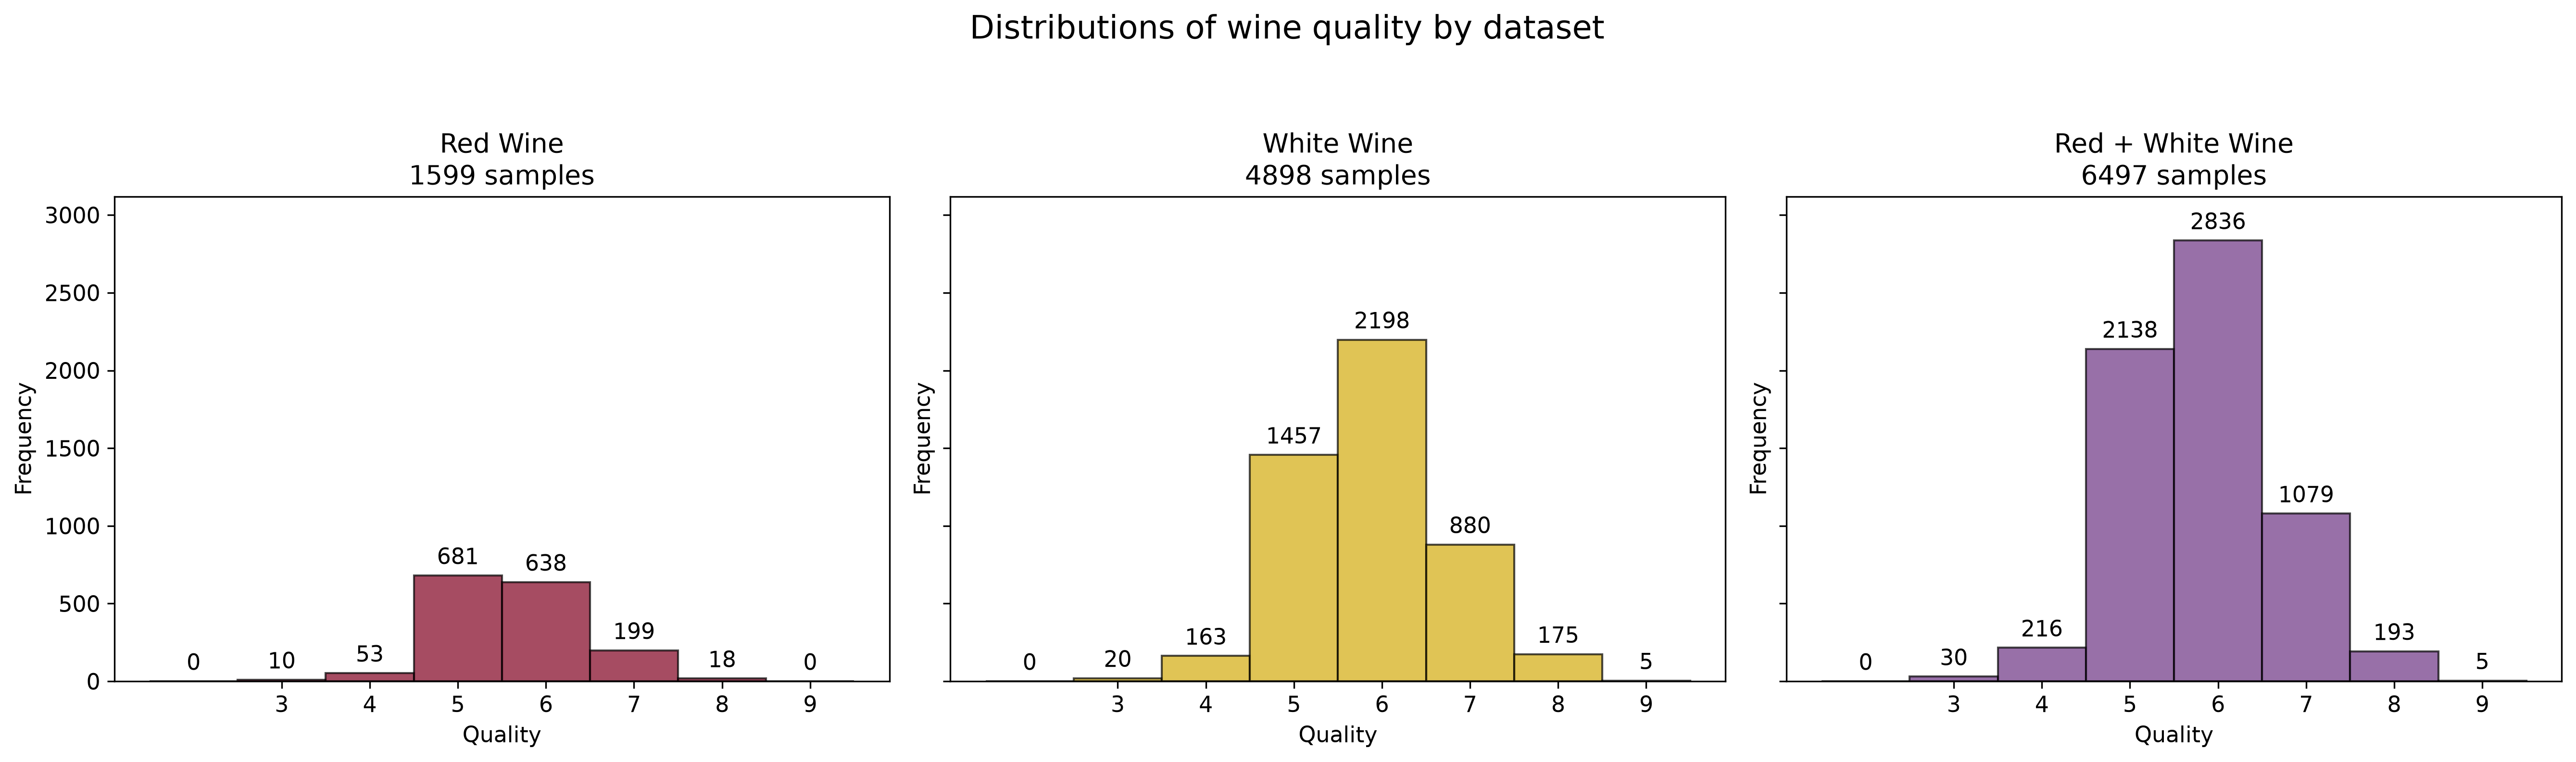

In [8]:
fig, axes = plt.subplots(1, len(datasets), figsize=(18, 5), sharey=True)

for ax, (name, (data, color)) in zip(axes, datasets.items()):
    _, _, bars = ax.hist(
        data["quality"],
        bins=np.arange(1.5, 10.5, 1),
        alpha=0.7,
        edgecolor="black",
        color=color
    )

    ax.bar_label(bars, fmt="%d", padding=3)     # shows the number above each bar
    ax.margins(y=0.1)                           # leaves space above the highest bar

    ax.set_xlabel("Quality")
    ax.set_ylabel("Frequency")
    ax.set_title(f"{name}\n{len(data)} samples")
    ax.set_xticks(range(3, 10))

fig.suptitle("Distributions of wine quality by dataset", fontsize=16, y=1.05)

plt.tight_layout()
plt.show()

# Save the figure
#fig.savefig("output/quality_distributions_hist.png", dpi=600, bbox_inches="tight")


*Figure 1: Counts of quality scores in the red, white and combined datasets. Each bar represents one score; labels give the number of samples.*

In [9]:
# Compare the quality counts and percentages for each dataset
quality_counts = pd.DataFrame(index=range(3, 10))
quality_counts.index.name = "Quality"

for name, (data, color) in datasets.items():
    quality_counts[name] = data["quality"].value_counts()

quality_counts = quality_counts.fillna(0).astype(int)
quality_percentages = quality_counts.div(quality_counts.sum()).mul(100).round(1)

print("Number of samples by quality")
display(quality_counts)
print("Percentage of samples by quality")
display(quality_percentages)

# A simple reference: always predict the most frequent score
majority_baselines = []
for name, (data, color) in datasets.items():
    counts = data["quality"].value_counts()
    majority_baselines.append({
        "Dataset": name,
        "Most frequent quality": counts.index[0],
        "Majority share (%)": round(counts.iloc[0] / len(data) * 100, 1)
    })

display(pd.DataFrame(majority_baselines).set_index("Dataset"))

Number of samples by quality


,Red Wine,White Wine,Red + White Wine
Quality,,,
3,10,20,30
4,53,163,216
5,681,1457,2138
6,638,2198,2836
7,199,880,1079
8,18,175,193
9,0,5,5


Percentage of samples by quality


,Red Wine,White Wine,Red + White Wine
Quality,,,
3,0.6,0.4,0.5
4,3.3,3.3,3.3
5,42.6,29.7,32.9
6,39.9,44.9,43.7
7,12.4,18.0,16.6
8,1.1,3.6,3.0
9,0.0,0.1,0.1


,Most frequent quality,Majority share (%)
Dataset,,
Red Wine,5,42.6
White Wine,6,44.9
Red + White Wine,6,43.7


Figure 1 shows that scores **5 and 6 dominate**: together they represent 76.6% of the combined dataset. The classes are unbalanced, with only five wines rated 9 (all white).

Always predicting 6 would match 43.7% of the combined observations. This is a descriptive reference, not a test result: the later baseline must learn the most frequent class from the training data only. We should also examine performance for each quality score, since accuracy alone could hide poor predictions for rare scores.

White wines account for 75.4% of all samples, so the combined results will be influenced more strongly by this group.

### Correlations

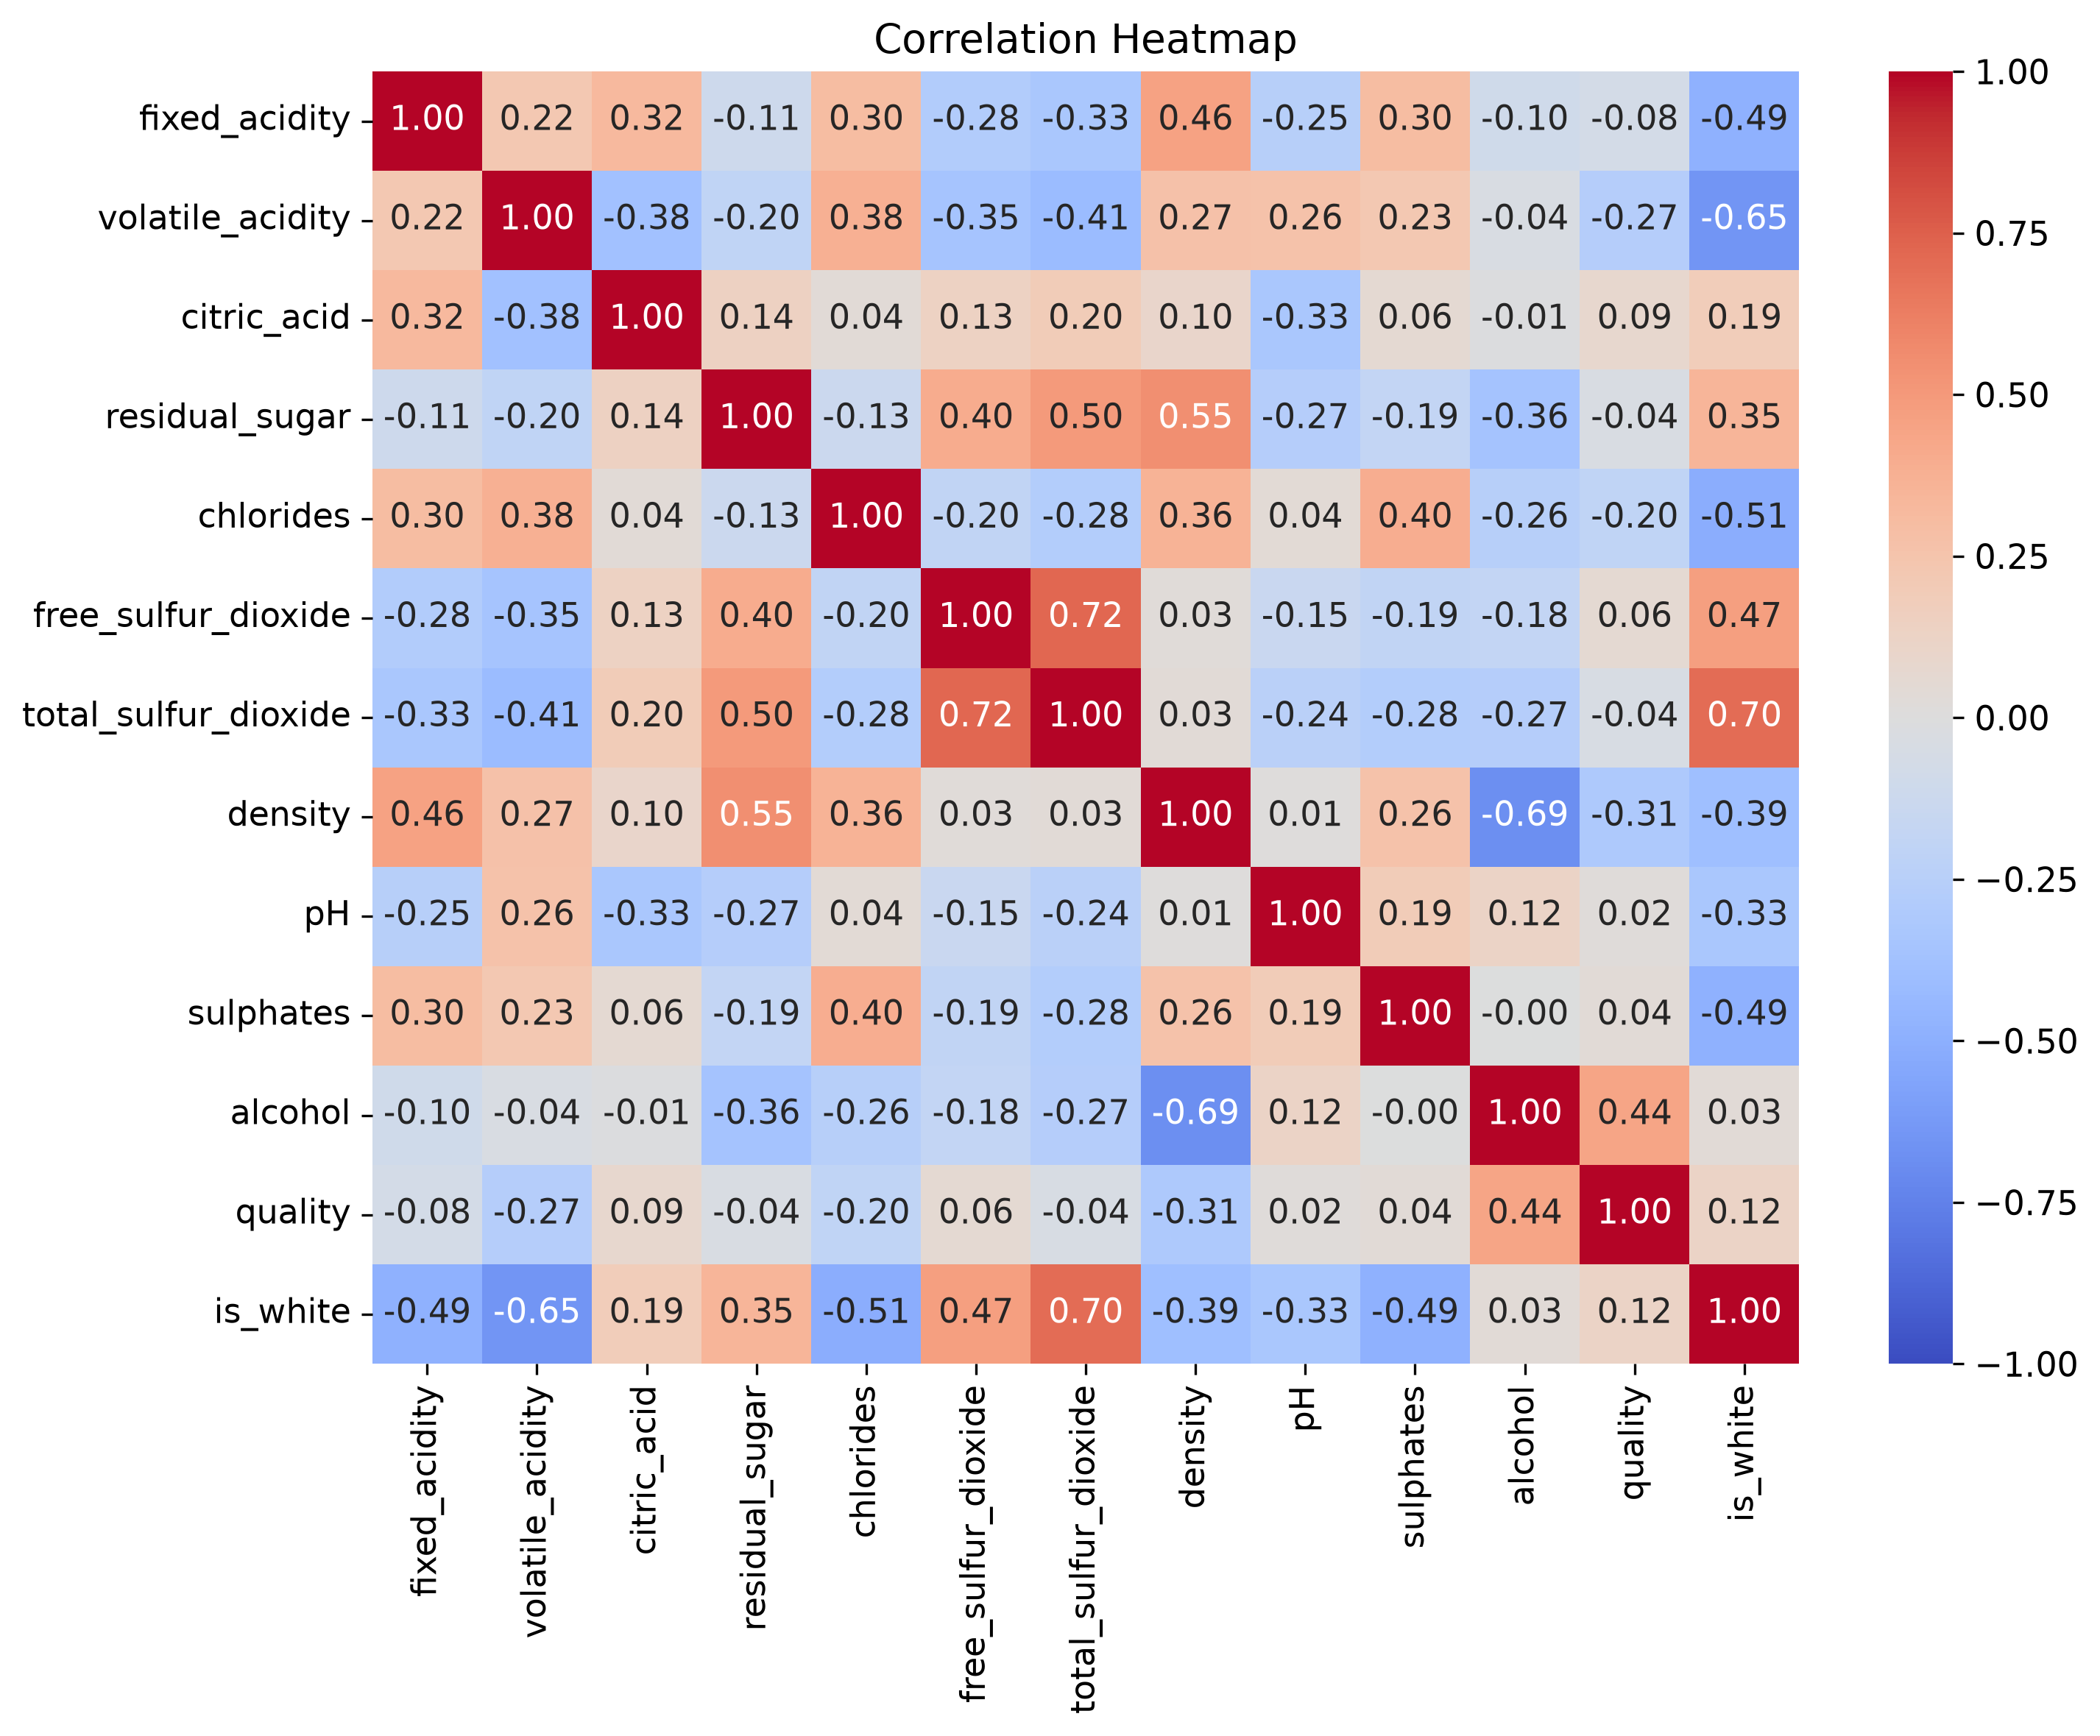

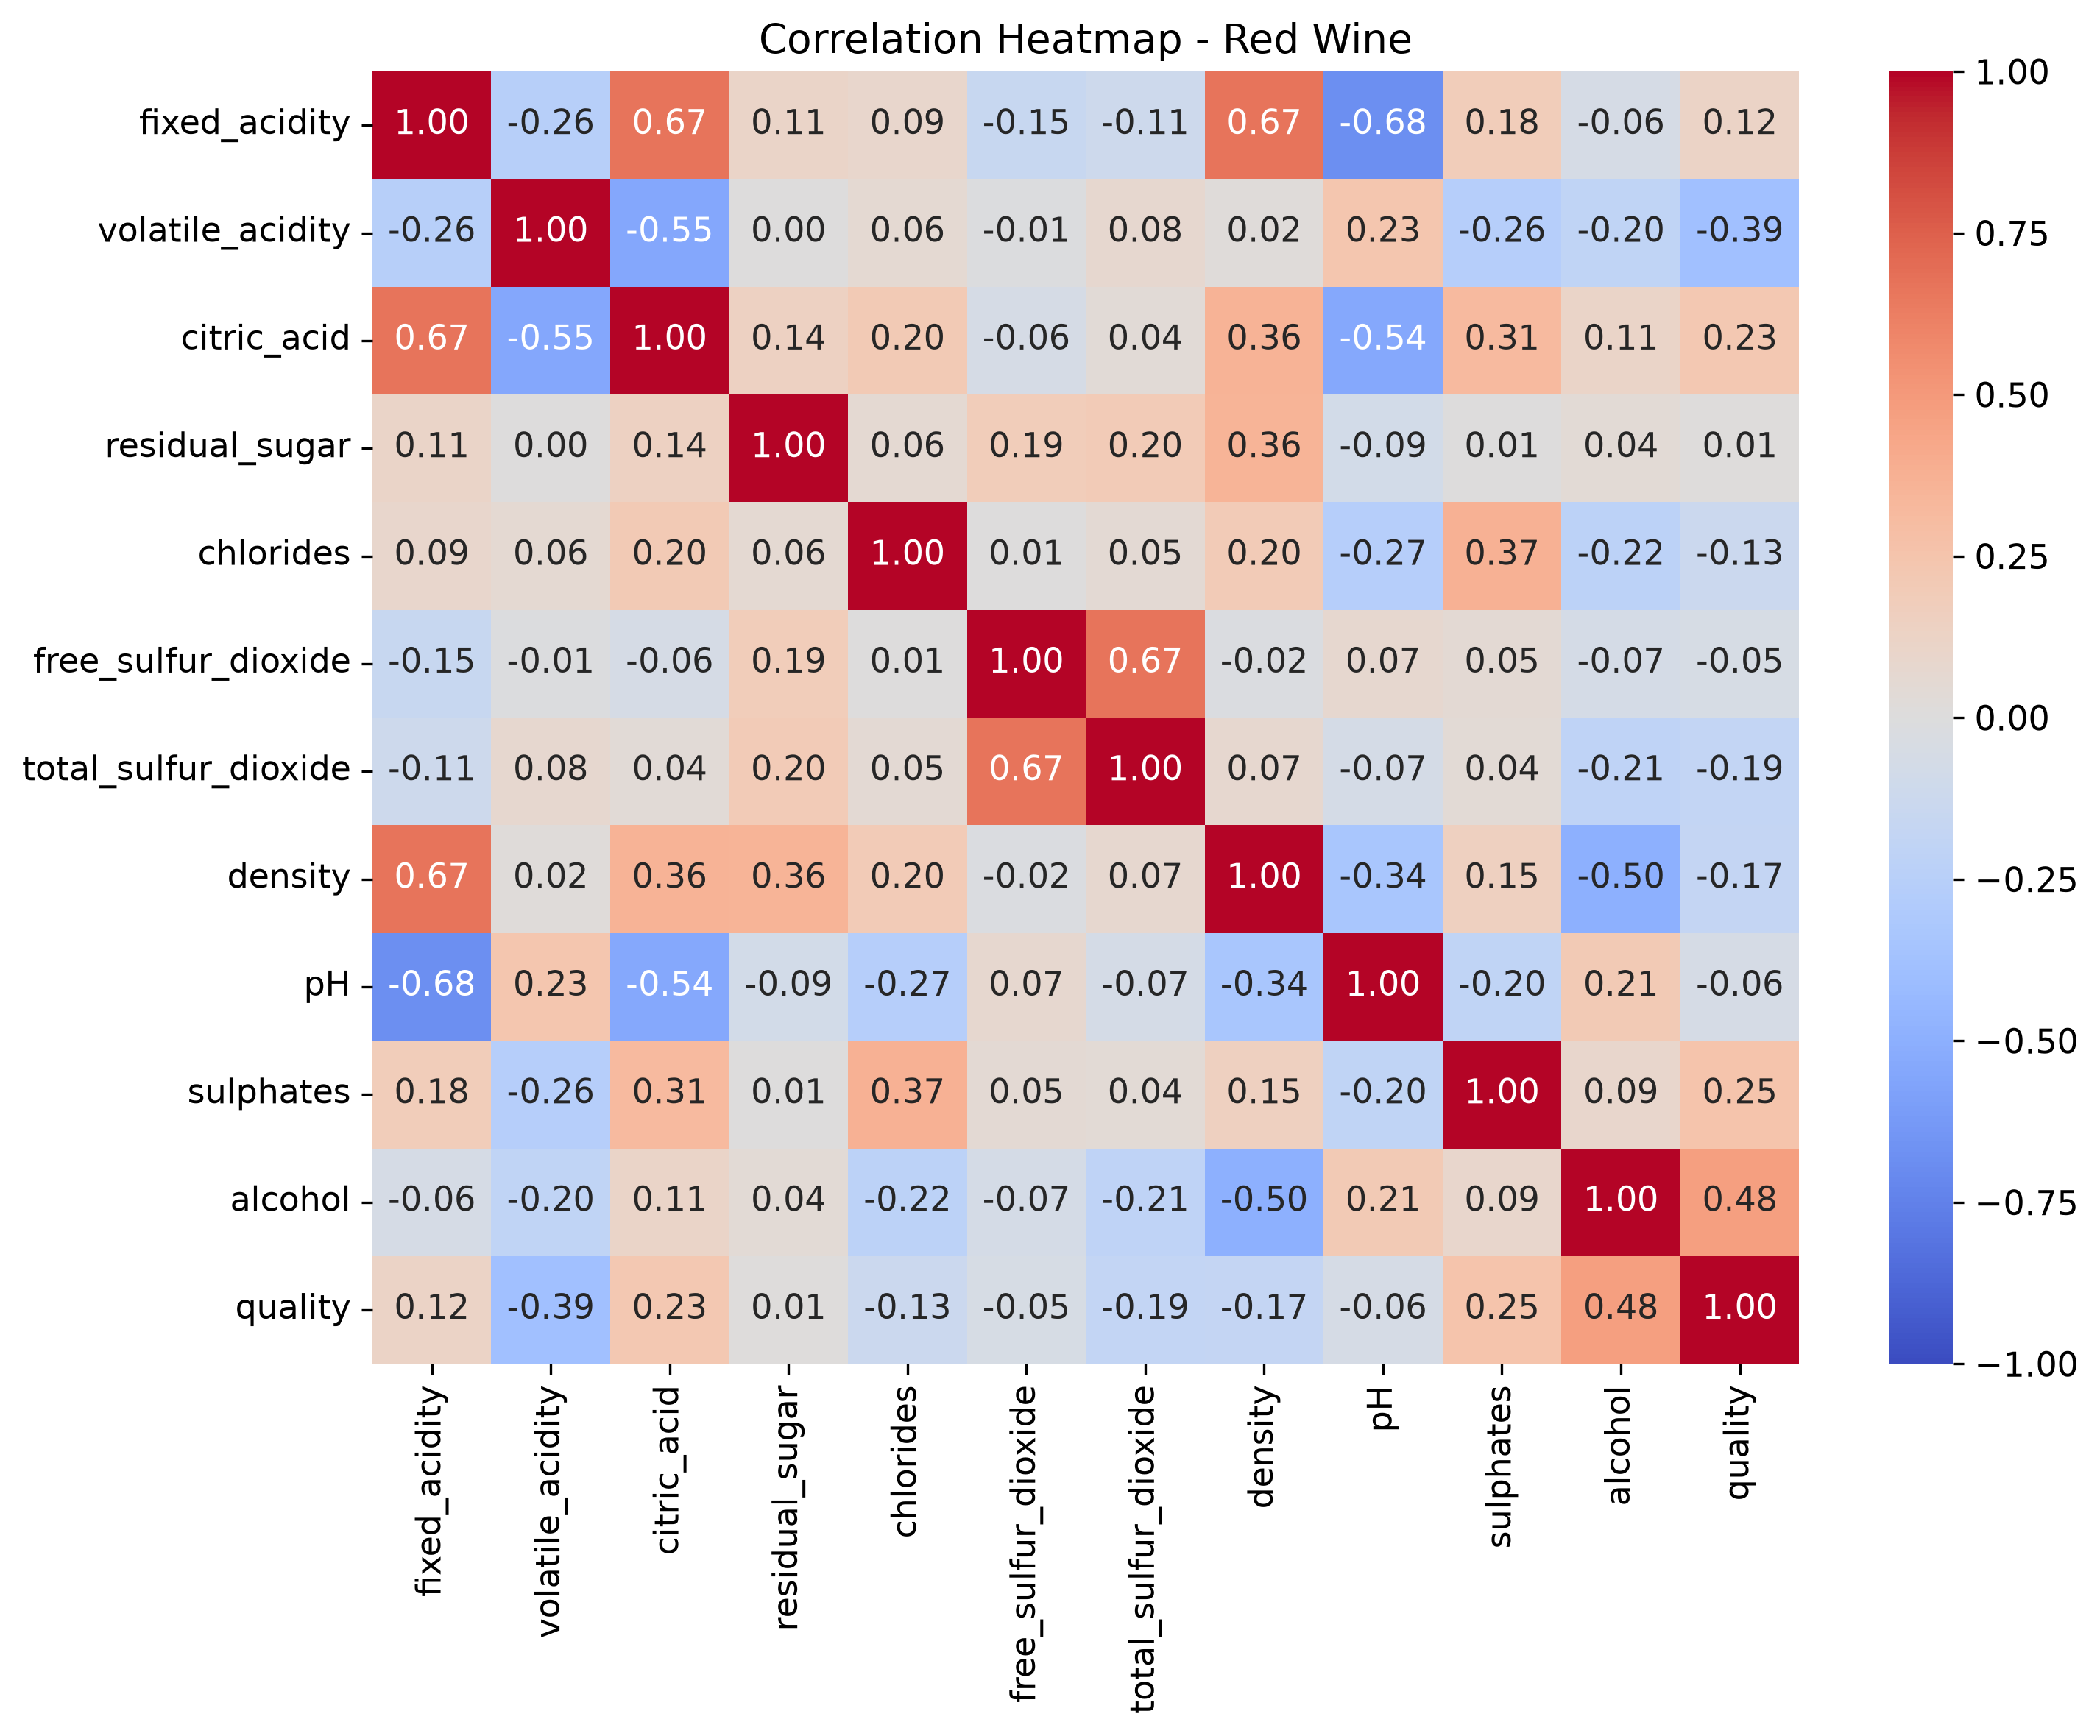

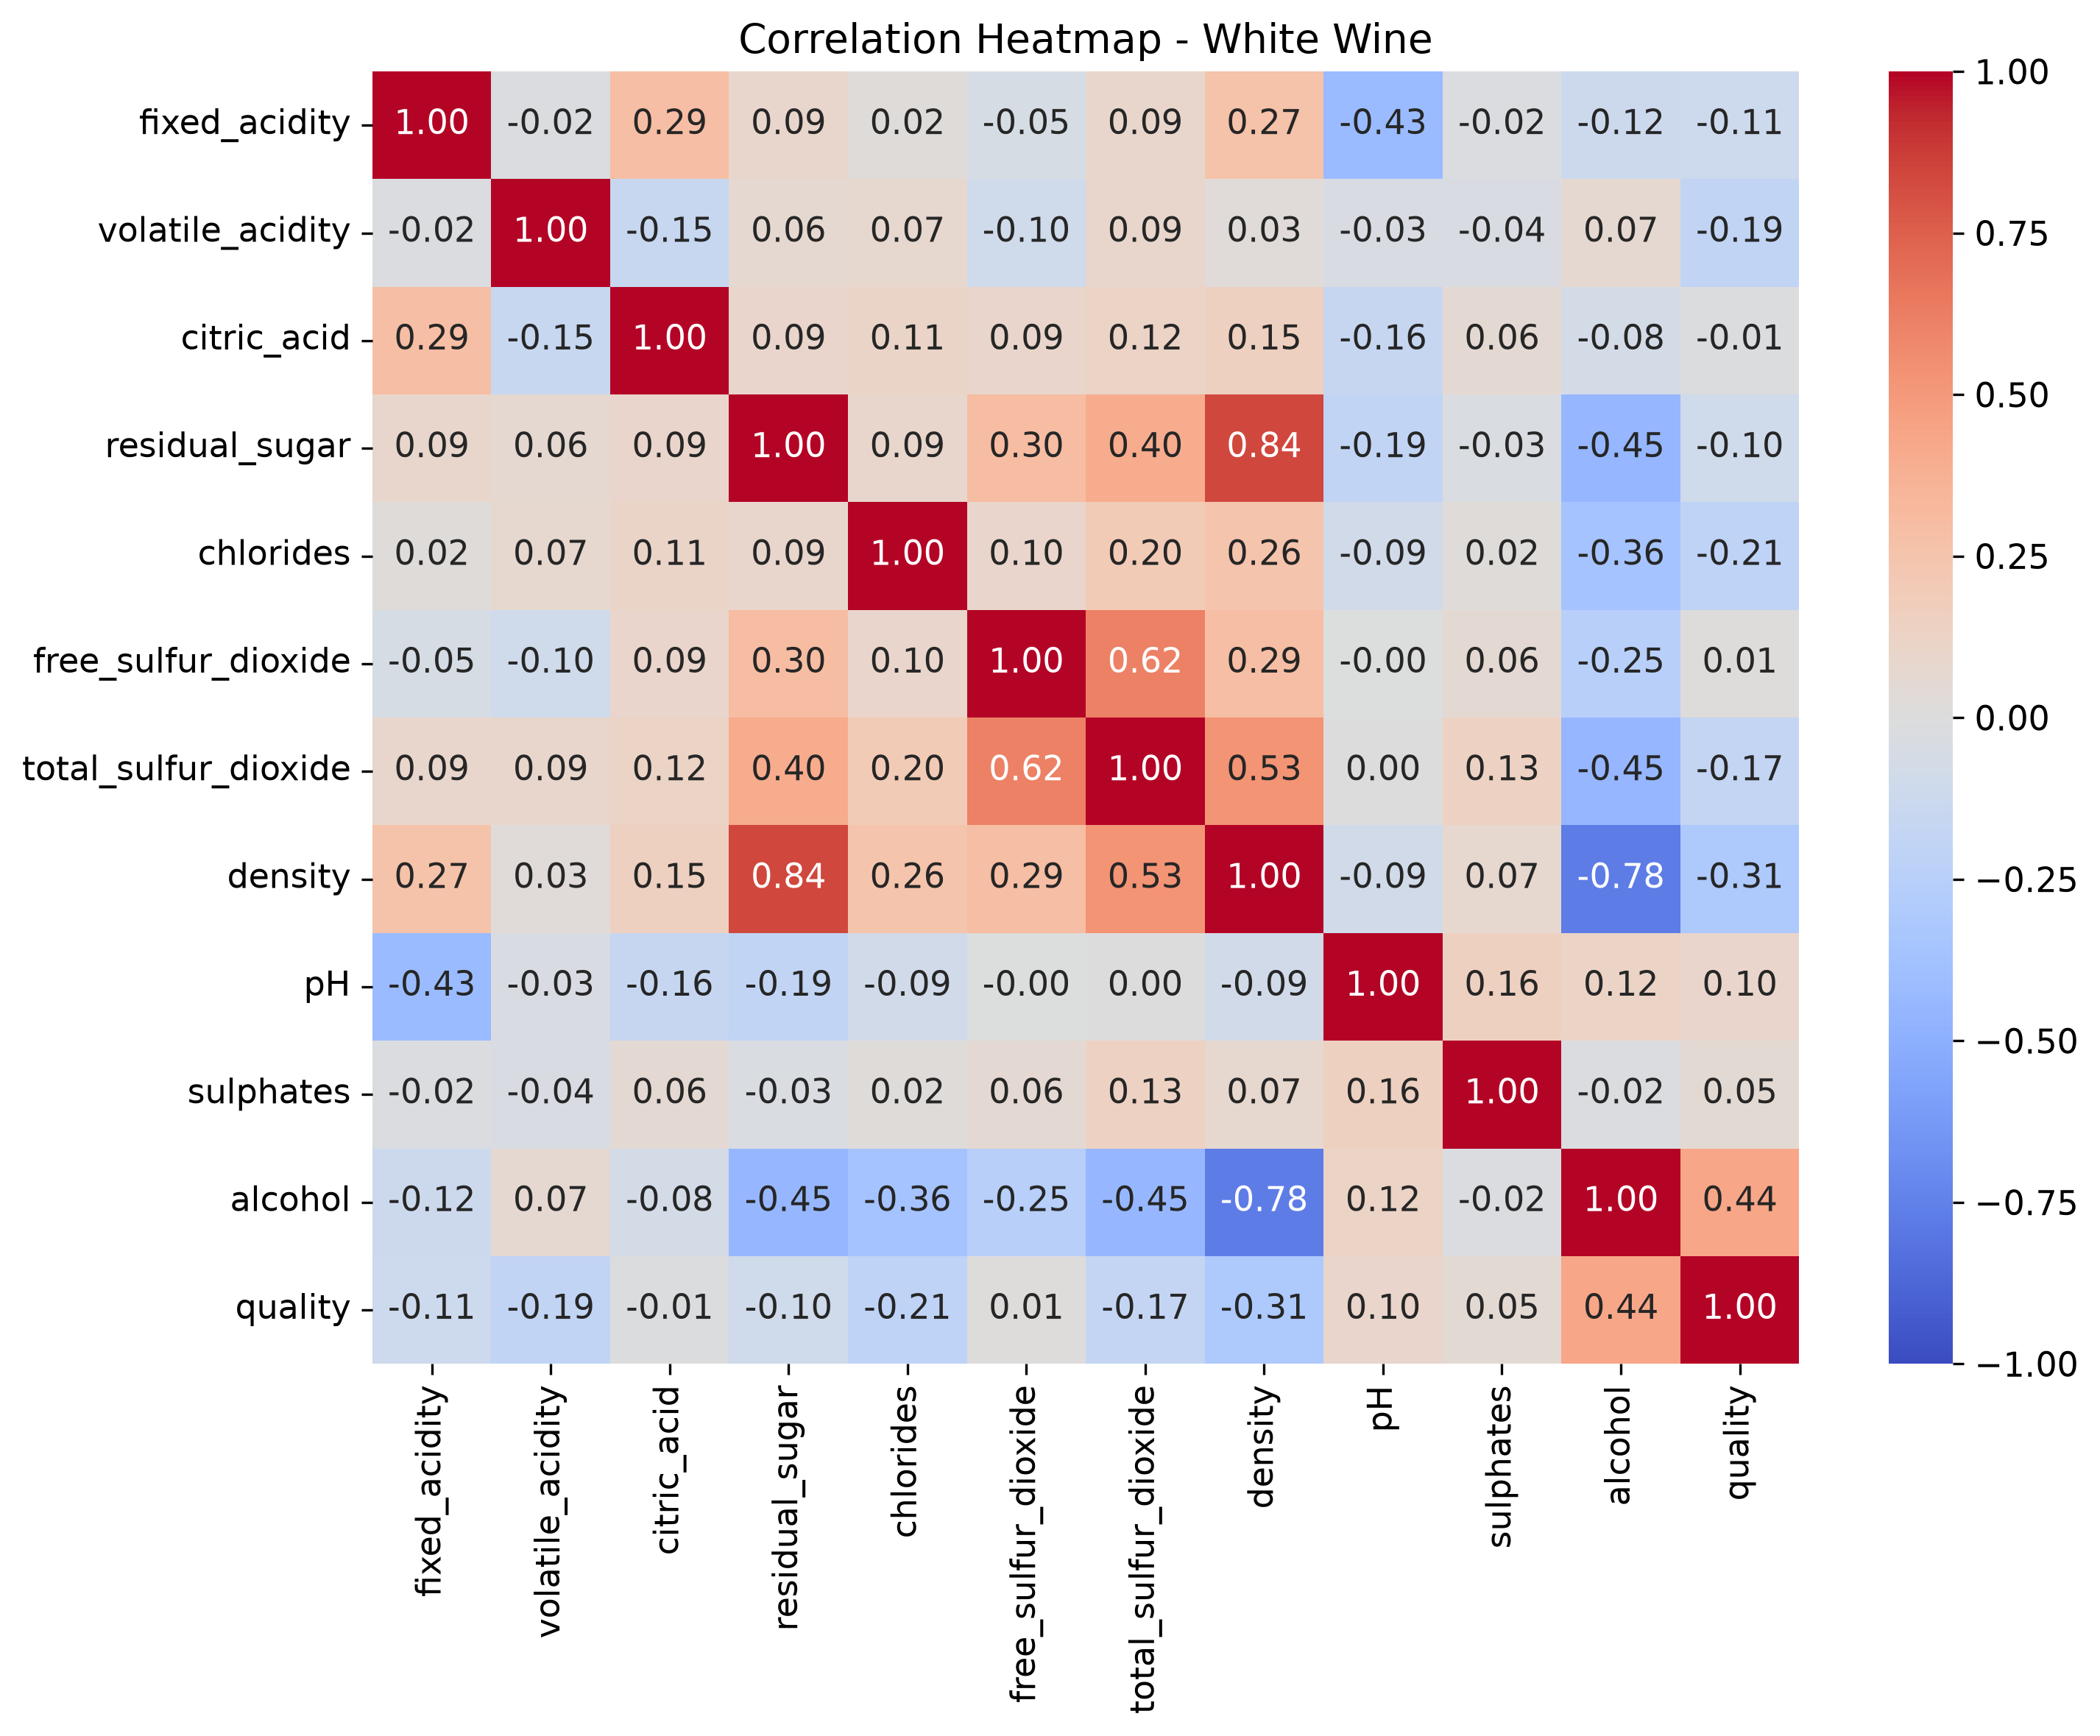

In [10]:
# Function to plot the correlation heatmap of a dataset
def plot_correlation_heatmap(dataset = fused_wine_data, title = "Correlation Heatmap", figsize = (10, 8), cmap = "coolwarm"):
    """
    Plots a correlation heatmap for the given dataset.

    Parameters:
    - dataset: pandas DataFrame containing the data. By default, it uses the fused wine dataset.
    - title: Title of the heatmap. By default, it is set to "Correlation Heatmap".
    - figsize: Size of the figure. By default, it is set to (10, 8).
    - cmap: Colormap to use for the heatmap. By default, it is set to "coolwarm".
    """
    plt.figure(figsize=figsize)
    numeric_dataset = dataset.select_dtypes(include="number") # Select only numeric columns for correlation calculation because correlation is not defined for non-numeric data
    correlation_matrix = numeric_dataset.corr()
    sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap=cmap, cbar=True, vmin=-1, vmax=1, center=0)
    plt.title(title)
    plt.tight_layout()
    plt.show()

plot_correlation_heatmap()
plot_correlation_heatmap(red_wine_data, title="Correlation Heatmap - Red Wine")
plot_correlation_heatmap(white_wine_data, title="Correlation Heatmap - White Wine")

*Figures 2-4: Pearson correlation matrices for the combined, red and white datasets, respectively. The same colour scale from -1 to 1 is used for all three heatmaps.*

In [11]:
# Compare the correlations with quality, keeping only the measurements
quality_correlations = pd.DataFrame()

for name, (data, color) in datasets.items():
    quality_correlations[name] = data[feature_columns + ["quality"]].corr()["quality"].drop("quality")

quality_correlations = quality_correlations.sort_values("Red + White Wine", ascending=False)
display(quality_correlations.round(3))

,Red Wine,White Wine,Red + White Wine
alcohol,0.476,0.436,0.444
citric_acid,0.226,-0.009,0.086
free_sulfur_dioxide,-0.051,0.008,0.055
sulphates,0.251,0.054,0.038
pH,-0.058,0.099,0.020
residual_sugar,0.014,-0.098,-0.037
total_sulfur_dioxide,-0.185,-0.175,-0.041
fixed_acidity,0.124,-0.114,-0.077
chlorides,-0.129,-0.210,-0.201
volatile_acidity,-0.391,-0.195,-0.266


In Figures 2-4, **alcohol has the strongest positive correlation with quality** among the measurements: 0.476 for red wines and 0.436 for white wines. In the combined data, density (-0.306) and volatile acidity (-0.266) have the strongest negative correlations with quality.

Some relationships change with wine type. For example, sulphates correlate with quality at 0.251 for red wines but only 0.054 for white wines. Total sulfur dioxide has a correlation around -0.18 in each separate dataset, but only -0.041 when they are combined. This makes the separate analyses useful alongside the combined one.

These are linear associations, not evidence of cause and effect. A weak correlation alone does not show that a measurement will be useless for an SVM.

### Measurements by quality
We now look at alcohol, volatile acidity, density and sulphates in more detail. The two wine types are shown separately to avoid hiding their differences.

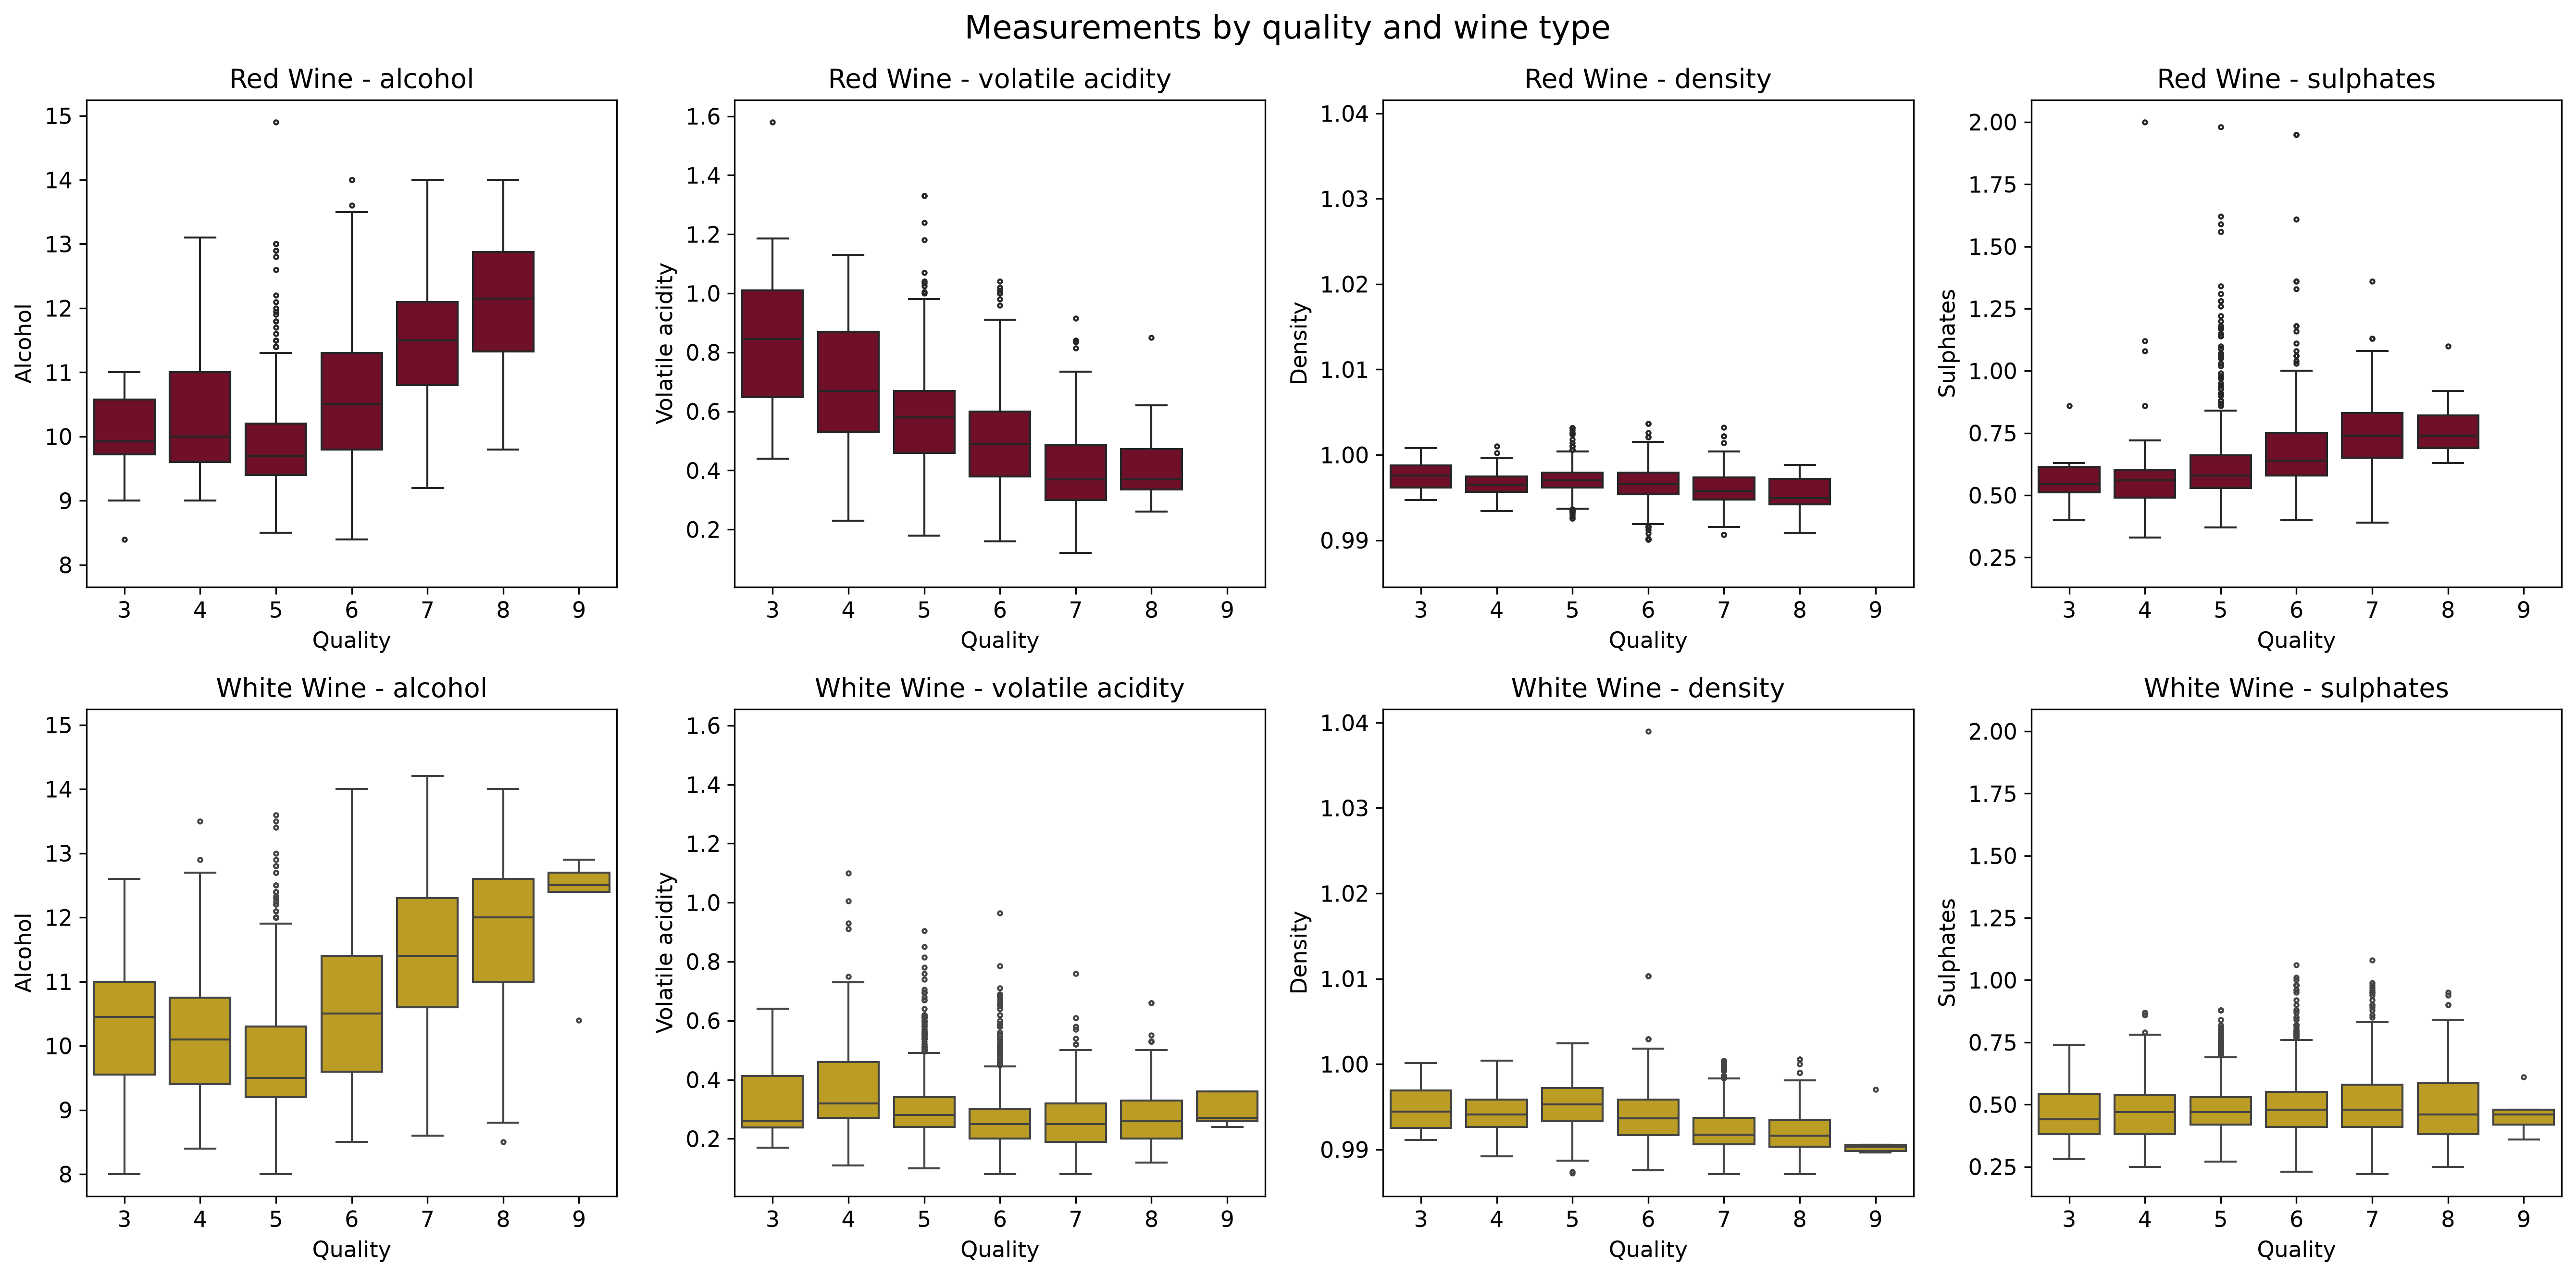

In [12]:
# One row per wine type, with the same vertical scale within each column
selected_features = ["alcohol", "volatile_acidity", "density", "sulphates"]
fig, axes = plt.subplots(2, len(selected_features), figsize=(18, 9), sharey="col")

for row, name in enumerate(["Red Wine", "White Wine"]):
    data, color = datasets[name]
    for ax, feature in zip(axes[row], selected_features):
        sns.boxplot(data=data, x="quality", y=feature, order=range(3, 10),
                    color=color, fliersize=2, linewidth=1, ax=ax)
        ax.set_title(f"{name} - {feature.replace('_', ' ')}")
        ax.set_xlabel("Quality")
        ax.set_ylabel(feature.replace("_", " ").capitalize())

fig.suptitle("Measurements by quality and wine type", fontsize=16)
plt.tight_layout()
plt.show()

*Figure 5: Boxplots of four measurements by quality score for red wines (top) and white wines (bottom). The middle line is the median, the box covers the middle 50% of observations, and the points beyond the whiskers show more extreme values. Empty positions indicate absent scores.*

In Figure 5, the median alcohol level generally increases with quality. For example, it rises from 9.7 at score 5 to 11.5 at score 7 for red wines, and from 9.5 to 11.4 for white wines. Lower volatile acidity and higher sulphates are more clearly associated with higher scores in red wines.

The boxes and whiskers still overlap between scores, so no single measurement gives a clean separation. The rare scores, especially 9 with only five samples, should be interpreted cautiously. Points outside the whiskers are not automatically errors.

### Red and white wine distributions
The histograms below use density rather than counts, so we can compare the shapes despite having many more white wines.

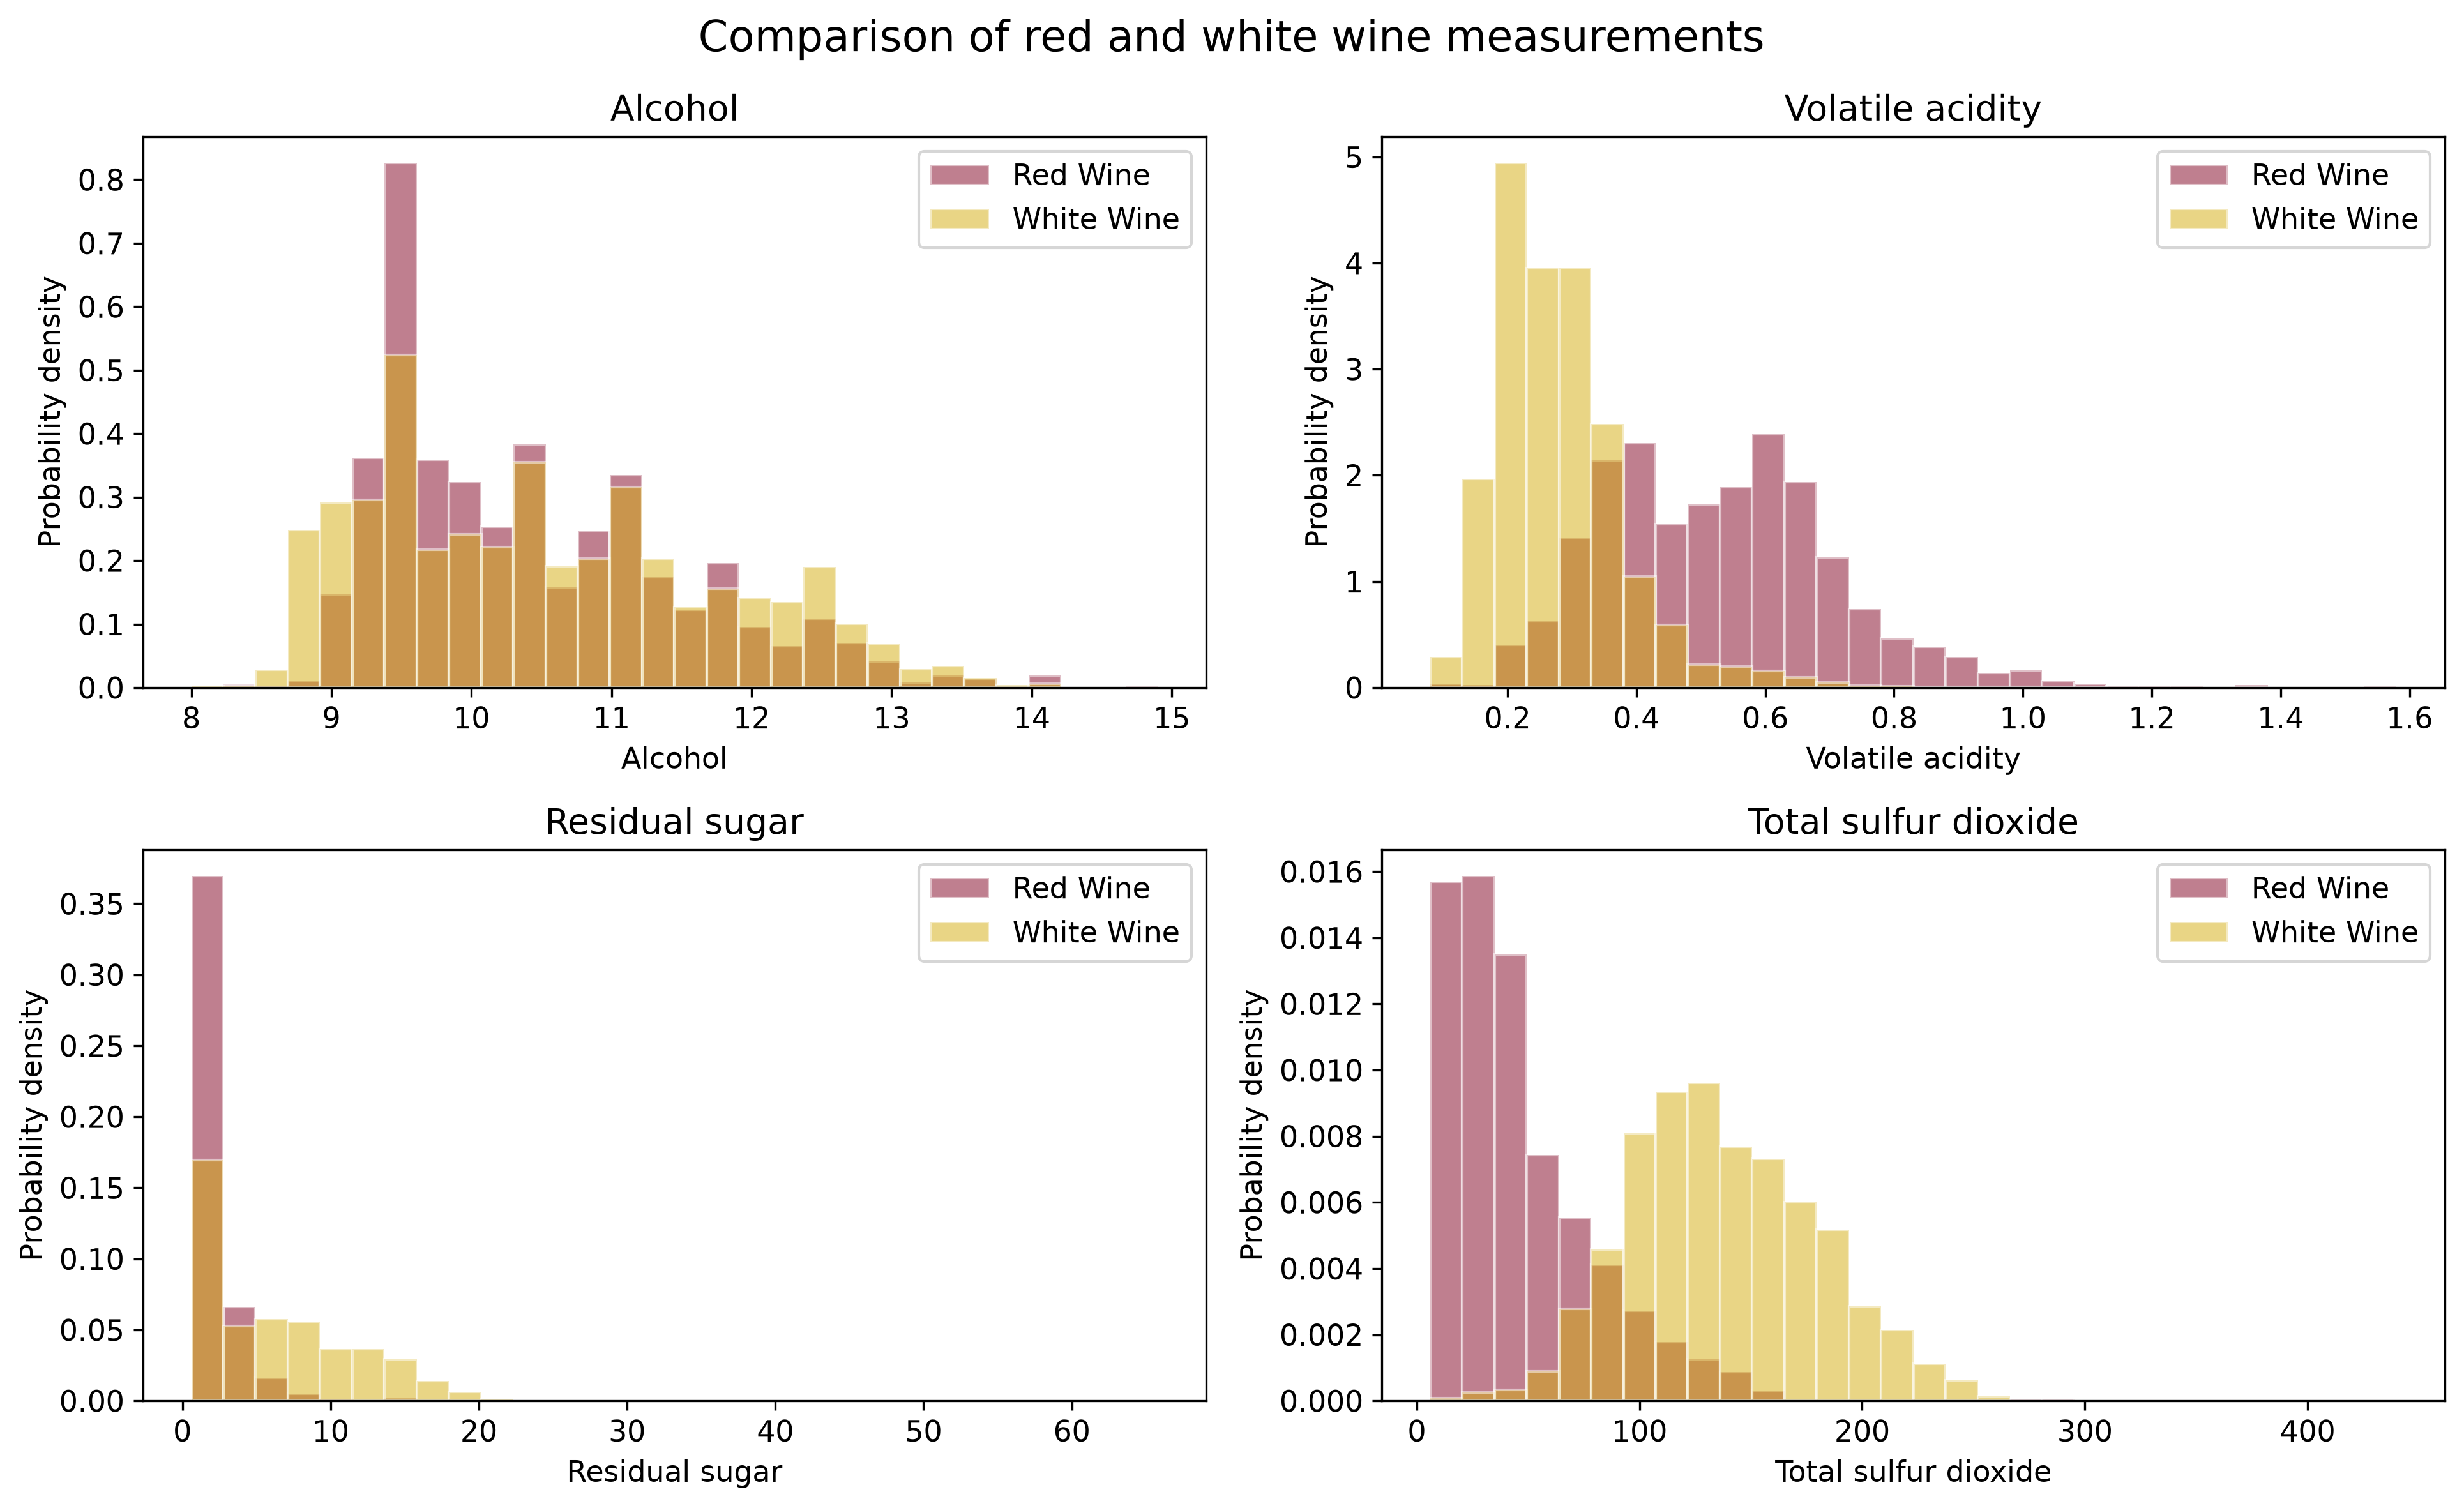

In [13]:
# Use the same bins for both wine types within each panel
comparison_features = ["alcohol", "volatile_acidity", "residual_sugar", "total_sulfur_dioxide"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for ax, feature in zip(axes.flat, comparison_features):
    bins = np.histogram_bin_edges(fused_wine_data[feature], bins=30)
    for name in ["Red Wine", "White Wine"]:
        data, color = datasets[name]
        ax.hist(data[feature], bins=bins, density=True, alpha=0.5,
                color=color, edgecolor="white", label=name)
    ax.set_title(feature.replace("_", " ").capitalize())
    ax.set_xlabel(feature.replace("_", " ").capitalize())
    ax.set_ylabel("Probability density")
    ax.legend()

fig.suptitle("Comparison of red and white wine measurements", fontsize=16)
plt.tight_layout()
plt.show()

*Figure 6: Overlaid histograms of four measurements for red and white wines, with 30 shared bins per panel. Each wine type is normalised separately so that its histogram has total area 1.*

Figure 6 shows that the alcohol distributions overlap strongly, while the other measurements differ more between types. White wines typically contain more residual sugar and total sulfur dioxide; red wines tend to have higher volatile acidity. The median residual sugar is 5.2 for white wines and 2.2 for red wines.

Residual sugar has a long right tail, especially for white wines. We keep the full range visible and retain these observations at this stage. These differences also explain why mixing both types can change the correlations seen earlier.

### Relationships between measurements
We use two scatter plots to see whether quality scores separate when looking at pairs of measurements.

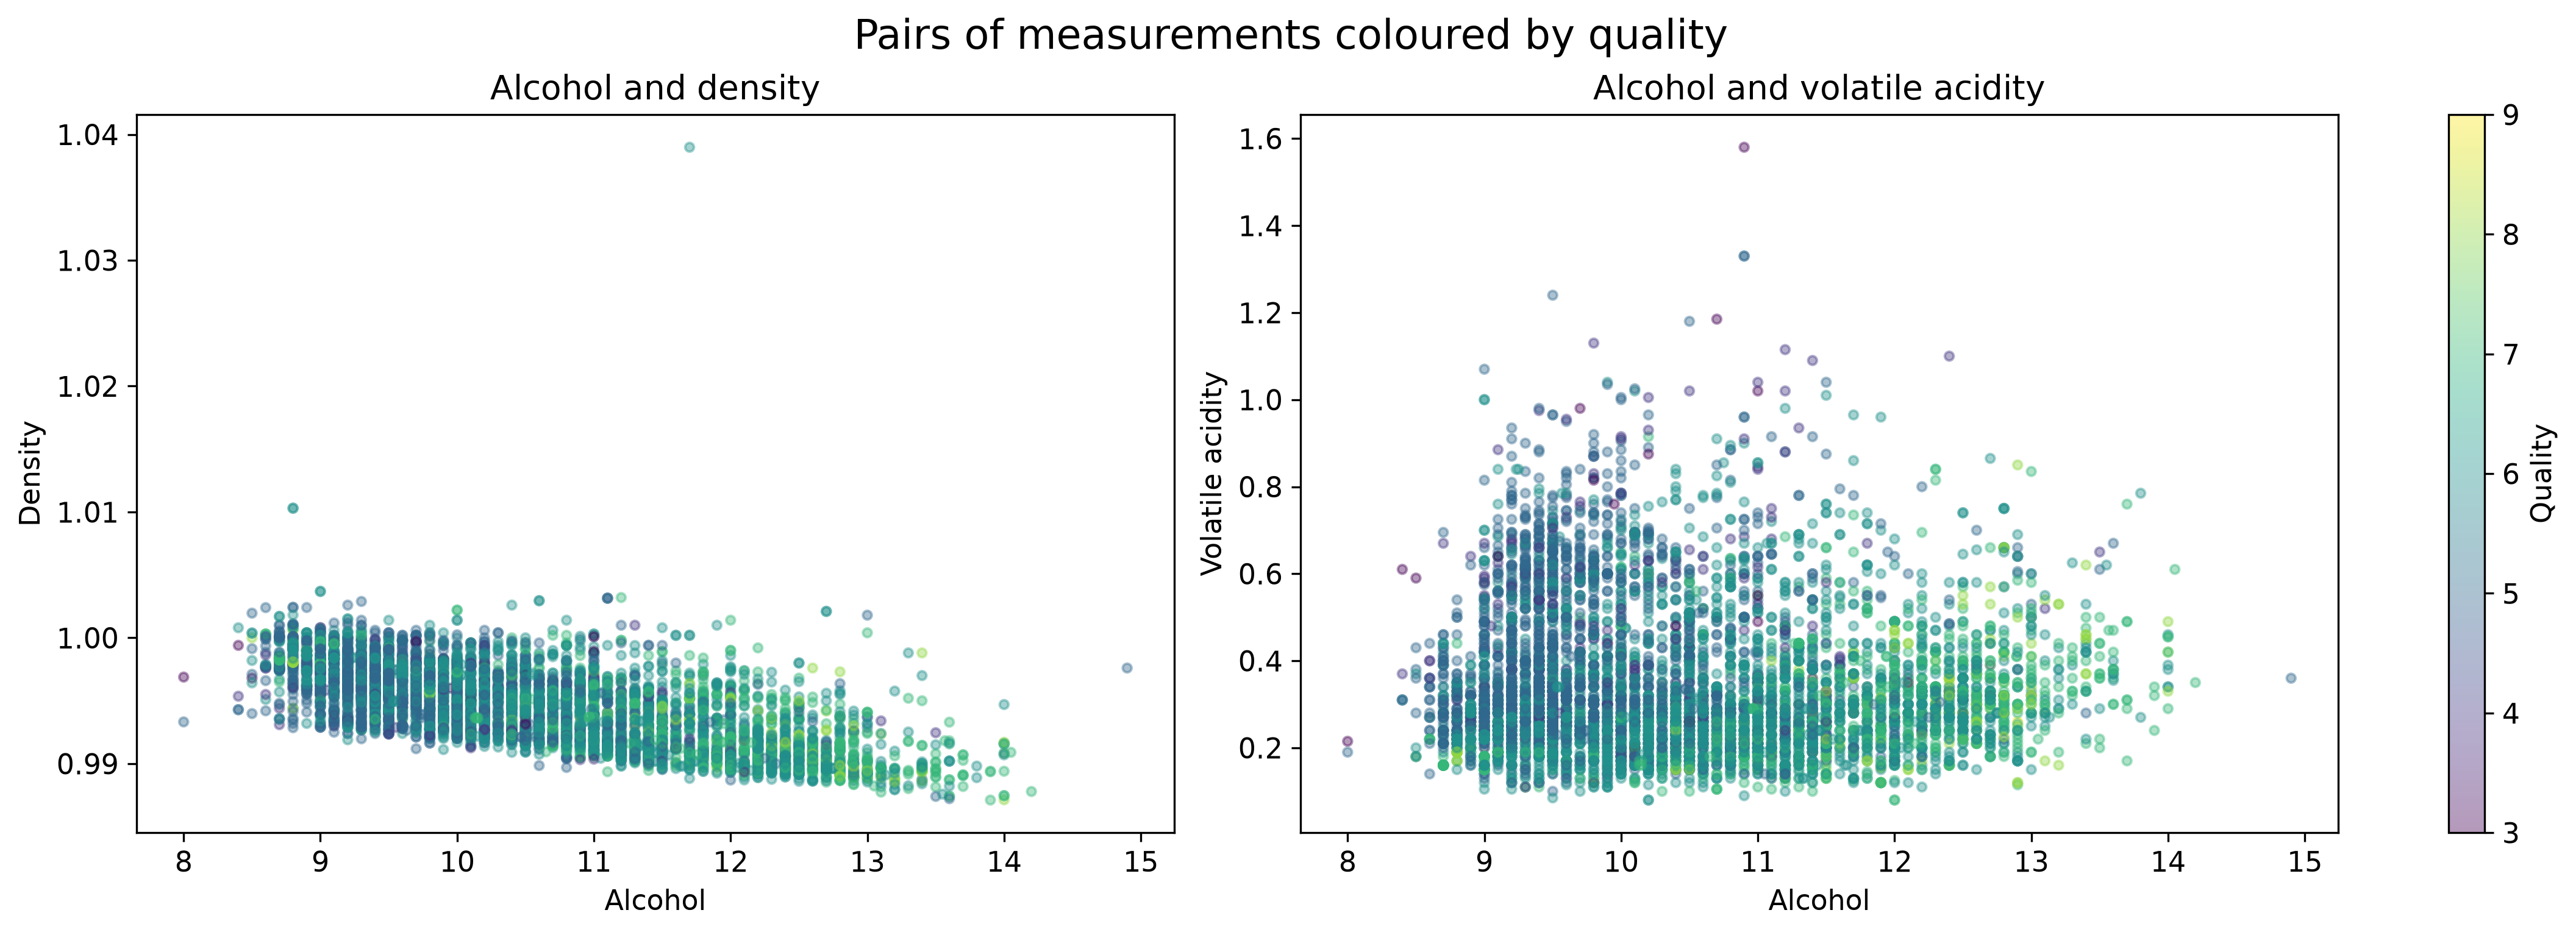

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

for ax, feature in zip(axes, ["density", "volatile_acidity"]):
    points = ax.scatter(fused_wine_data["alcohol"], fused_wine_data[feature],
                        c=fused_wine_data["quality"], cmap="viridis",
                        vmin=3, vmax=9, s=12, alpha=0.4)
    ax.set_xlabel("Alcohol")
    ax.set_ylabel(feature.replace("_", " ").capitalize())
    ax.set_title(f"Alcohol and {feature.replace('_', ' ')}")

fig.colorbar(points, ax=axes, label="Quality", ticks=range(3, 10))
fig.suptitle("Pairs of measurements coloured by quality", fontsize=16)
plt.show()

*Figure 7: Alcohol against density (left) and volatile acidity (right) for the combined dataset. Each point is an observation; its colour represents the quality score. Transparency helps show overlapping observations.*

In Figure 7, higher alcohol is often associated with lower density. Higher-quality wines tend to appear towards higher alcohol values, but the colours overlap considerably in both panels. These two measurements alone do not clearly separate the quality scores.

### A two-dimensional PCA overview
PCA combines measurements into new axes that capture as much variation as possible. Here we use it only to visualise the data, not to train or evaluate a classifier.

We standardise the 11 measurements first because their scales differ. We exclude `quality`, `type` and `is_white` from the PCA inputs; quality and wine type are used only to colour the plots.

Variance explained by PC1: 27.5%
Variance explained by PC2: 22.7%
Total variance explained: 50.2%


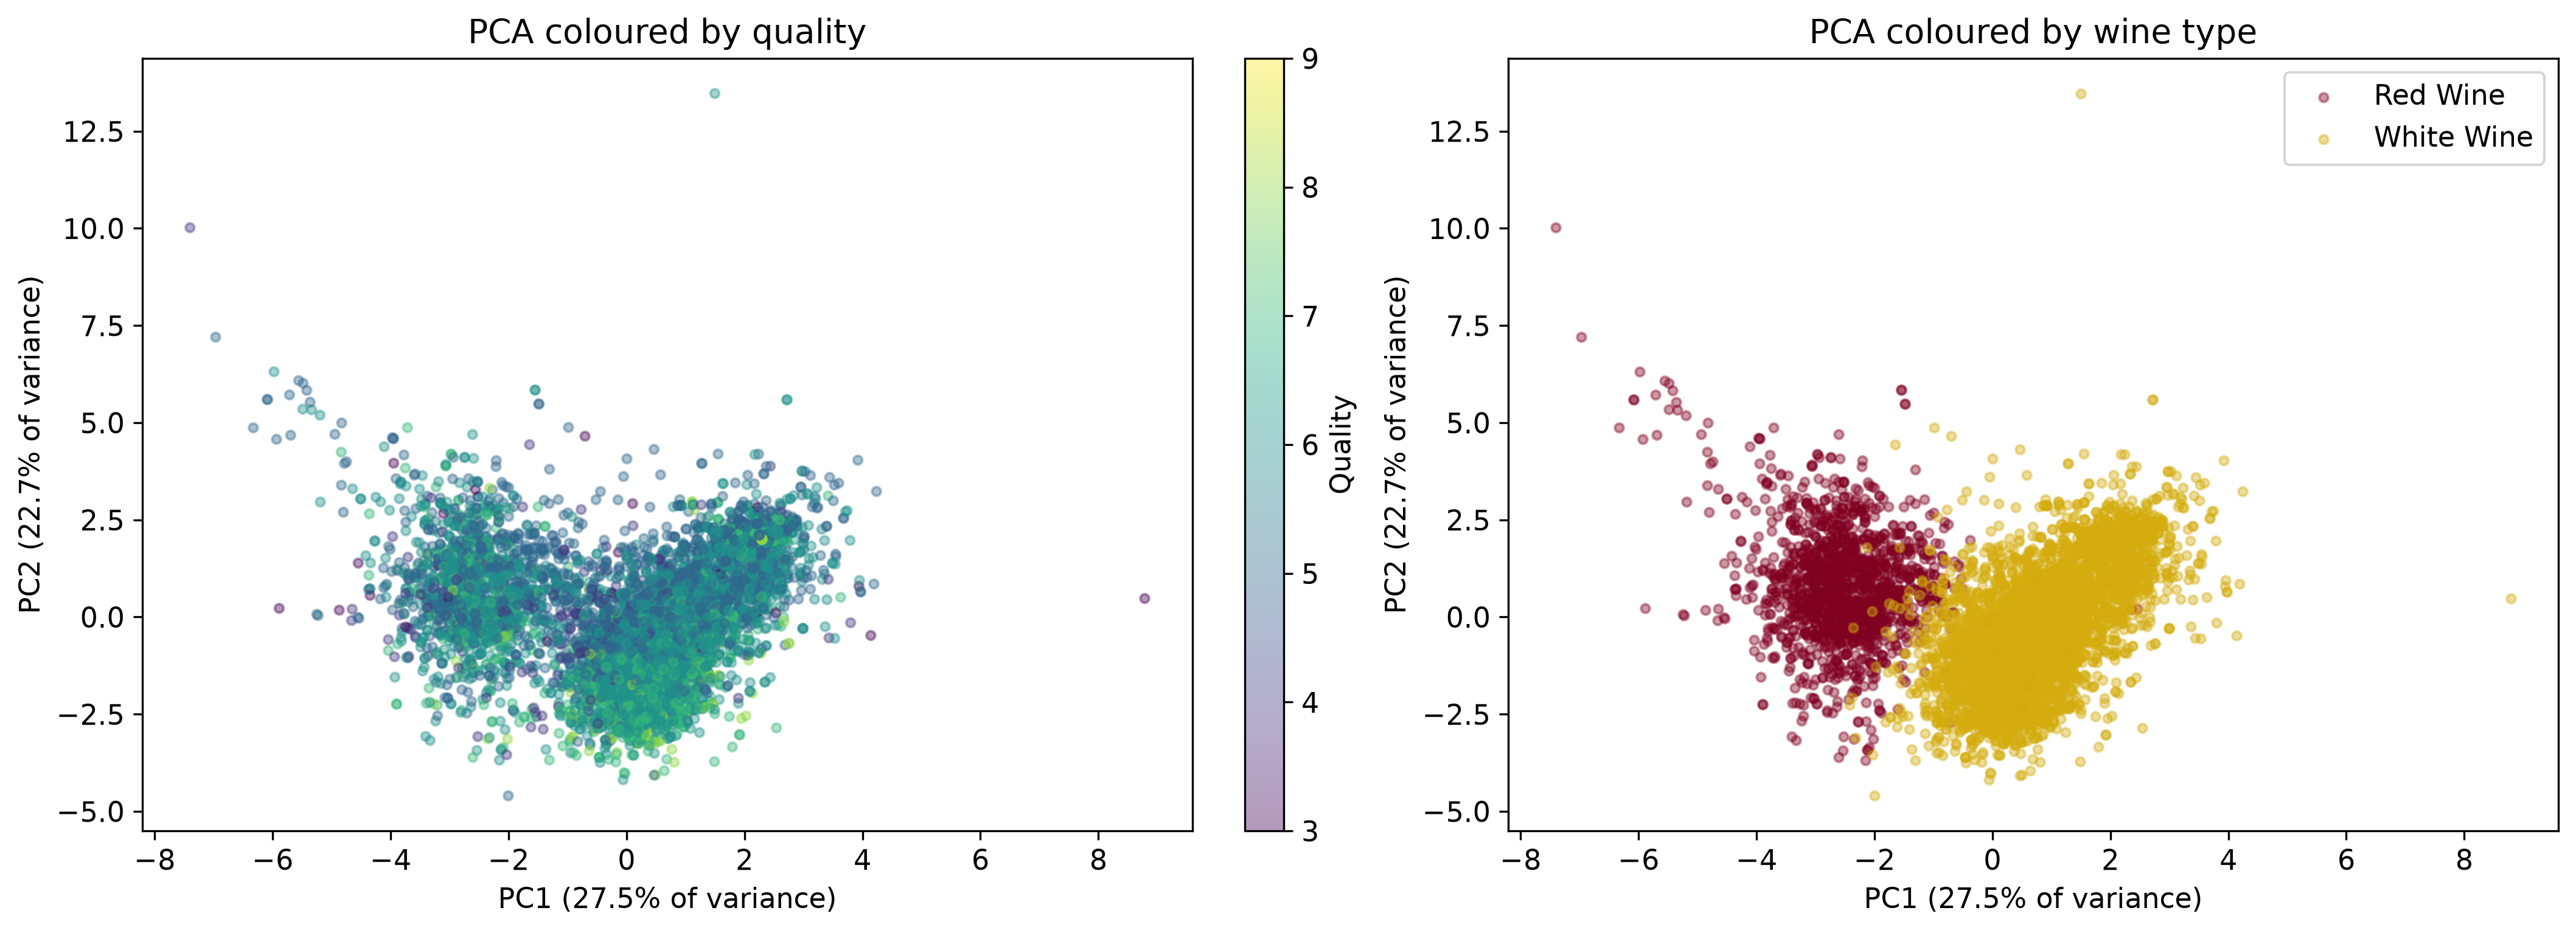

In [15]:
# This scaling uses all rows for exploration only
# For model evaluation, fit the scaler on the training set only
scaler = StandardScaler()
scaled_measurements = scaler.fit_transform(fused_wine_data[feature_columns])

pca = PCA(n_components=2)
pca_coordinates = pca.fit_transform(scaled_measurements)
explained_variance = pca.explained_variance_ratio_ * 100

print(f"Variance explained by PC1: {explained_variance[0]:.1f}%")
print(f"Variance explained by PC2: {explained_variance[1]:.1f}%")
print(f"Total variance explained: {explained_variance.sum():.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

points = axes[0].scatter(pca_coordinates[:, 0], pca_coordinates[:, 1],
                         c=fused_wine_data["quality"], cmap="viridis",
                         vmin=3, vmax=9, s=12, alpha=0.4)
fig.colorbar(points, ax=axes[0], label="Quality", ticks=range(3, 10))
axes[0].set_title("PCA coloured by quality")

for name, wine_type in [("Red Wine", "red"), ("White Wine", "white")]:
    mask = fused_wine_data["type"] == wine_type
    axes[1].scatter(pca_coordinates[mask, 0], pca_coordinates[mask, 1],
                    color=datasets[name][1], label=name, s=12, alpha=0.4)
axes[1].set_title("PCA coloured by wine type")
axes[1].legend()

for ax in axes:
    ax.set_xlabel(f"PC1 ({explained_variance[0]:.1f}% of variance)")
    ax.set_ylabel(f"PC2 ({explained_variance[1]:.1f}% of variance)")

plt.show()

*Figure 8: The same two-component PCA projection of the 11 standardised measurements, coloured by quality (left) and wine type (right). PCA is fitted without the quality scores or wine-type indicators.*

The first two components explain **50.2% of the variation** in the standardised measurements. In Figure 8, red and white wines form more distinct groups than the quality scores, which overlap strongly. Wine type therefore describes a visible difference in composition, while quality is harder to separate in this view.

About half of the variation is outside these two axes. This plot does not tell us how well an SVM will perform, and it does not mean that only two components should be used for modelling.

### What this means for the SVM demonstration
- Predict `quality` using the measurements. For a combined model, consider adding `is_white`; `type` contains the same information.
- Handle the repeated rows before splitting, to avoid identical observations appearing in both training and test data.
- Keep a separate test set and preserve the quality proportions when possible. The rarest scores will still have very few test examples.
- Fit preprocessing on the training data only. The scaling and PCA above are for exploration and should not be reused for test-set evaluation.
- Compare the SVM against a majority-class baseline and look at a confusion matrix and per-class results, as well as overall accuracy.
- Alcohol, density and volatile acidity show useful associations, but we keep all 11 measurements as a starting point. Any feature selection or parameter tuning should use only the training data.

The initial exploration is complete. No SVM has been trained yet.

Dataset reference: P. Cortez, A. Cerdeira, F. Almeida, T. Matos and J. Reis (2009), *Modeling wine preferences by data mining from physicochemical properties*, Decision Support Systems, 47(4), 547-553. The dataset description is included in `data/winequality.names`.